# Análise de Risco de Crédito
---
   1. Baixa os dados abertos do Banco Central (SCR), um .zip por ano.
   2. Abre os .zip e lê os .csv de dentro.
   3. Deixa só o que interessa (Pessoa Física) e arruma as colunas.
   4. Faz as duas análises que já estão prontas:
        - Inadimplência alta vs recuperação rápida
        - Dívida saudável vs crítica
      Cada uma desenha um gráfico no Colab (pra gente conferir os números).

---

Bibliotecas

---

In [ ]:
import pandas as pd                 # tabelas (DataFrames): é com ela que a gente soma, filtra e agrupa
import requests                     # baixar arquivos e falar com o servidor pela internet
import zipfile                      # abrir arquivos .zip
import os                           # criar pastas e listar arquivos
import time                         # esperar alguns segundos entre uma tentativa e outra de download
import matplotlib.pyplot as plt     # desenhar os gráficos
from concurrent.futures import ThreadPoolExecutor as tpe   # baixar vários arquivos ao mesmo tempo
from tqdm.auto import tqdm          # barrinha de progresso nos laços demorados

---

Configurações

---

In [ ]:
# Anos que vão ser baixados do Banco Central (quanto mais anos, mais demora)
anos = list(range(2024, 2026 + 1))   # range(2024, 2027) dá 2024, 2025 e 2026

# Pastas usadas no Colab
pasta_ext = "/content/dados_scr_extraidos"   # onde os .csv extraídos ficam

# Cria as pastas se elas ainda não existirem (exist_ok=True evita erro se já existirem)
os.makedirs(pasta_ext, exist_ok=True)

---

Download e extração dos arquivos do Banco Central

---

In [ ]:
def baixar_zip(ano):
    # Monta o endereço do .zip daquele ano
    url = f"https://www.bcb.gov.br/pda/desig/scrdata_{ano}.zip"

    # Caminho onde o .zip vai ficar salvo no Colab
    caminho = f"/content/scrdata_{ano}.zip"

    # Se a internet oscilar, tentamos de novo em vez de desistir de cara
    tentativas = 5

    for tentativa in range(1, tentativas + 1):
        try:
            # stream=True baixa aos poucos, sem carregar o arquivo inteiro na memória
            resposta = requests.get(url, stream=True)
            # Se o site respondeu com erro (404, 500...), isso gera uma exceção
            resposta.raise_for_status()

            # "wb" = escrever em modo binário (.zip não é texto)
            with open(caminho, "wb") as arquivo:
                # Grava o arquivo em pedaços de 1 MB (1024 * 1024 bytes)
                for pedaco in resposta.iter_content(chunk_size=1024 * 1024):
                    arquivo.write(pedaco)

            return caminho   # deu certo: devolve o caminho e sai da função

        except Exception as erro:
            # Deu erro: avisa qual tentativa falhou
            print(f"Ano {ano}: tentativa {tentativa} de {tentativas} falhou ({erro}).")
            if tentativa < tentativas:
                time.sleep(3)   # espera 3 segundos antes de tentar de novo

    # Chegou aqui = as 5 tentativas falharam. Devolve None (vazio) pra pular esse ano
    print(f"Não foi possível baixar {ano}. Pulando este ano.")
    return None

In [ ]:
# Baixa os anos ao mesmo tempo pra ir mais rápido.
# ThreadPoolExecutor é um "grupo de ajudantes": cada um baixa um ano.
# max_workers=3 -> no máximo 3 downloads rodando juntos, um por ano.
# executor.map(baixar_zip, anos) -> chama baixar_zip(ano) pra cada ano da lista
# e devolve os resultados na mesma ordem dos anos.
with tpe(max_workers=3) as executor:
    resultados = list(tqdm(executor.map(baixar_zip, anos), total=len(anos), desc="Baixando anos"))

# Fica só com os que deram certo (os anos que falharam voltam como None)
zips_baixados = [caminho for caminho in resultados if caminho is not None]
print("Anos baixados com sucesso:", zips_baixados)

# Abre cada .zip e joga os .csv de dentro na pasta de extração
for caminho_zip in tqdm(zips_baixados, desc="Extraindo arquivos ZIP"):
    with zipfile.ZipFile(caminho_zip, "r") as zip_aberto:   # "r" = só leitura
        zip_aberto.extractall(pasta_ext)

# Lista só os arquivos que terminam em .csv
arquivos_csv = [nome for nome in os.listdir(pasta_ext) if nome.endswith(".csv")]
print("Total de arquivos CSV extraídos (todos os anos):", len(arquivos_csv))

Baixando anos:   0%|          | 0/3 [00:00<?, ?it/s]

Anos baixados com sucesso: ['/content/scrdata_2024.zip', '/content/scrdata_2025.zip', '/content/scrdata_2026.zip']


Extraindo arquivos ZIP:   0%|          | 0/3 [00:00<?, ?it/s]

Total de arquivos CSV extraídos (todos os anos): 31


---

Leitura dos CSVs

---

In [ ]:
# Colunas do CSV que interessam (as outras nem são carregadas)
colunas = [
    "data_base",                 # mês de referência
    "uf",                        # estado
    "cliente",                   # PF (pessoa física) ou PJ (pessoa jurídica)
    "porte",                     # faixa de renda (usada pra achar o público vulnerável)
    "carteira_a_vencer",
    "carteira_inadimplencia",    # dívida com atraso grande (inadimplência alta)
    "a_vencer_ate_90_dias",      # dívida que vence em até 90 dias (recuperação rápida)
    "carteira_ativa",            # total da carteira de crédito
    "modalidade",
    "submodalidade",             # tipo de crédito (cartão, financiamento de imóvel...)
    "ativo_problematico",
]

# Faixas de renda (coluna "porte" do SCR) que contam como público vulnerável
# ("Sem rendimento" entra porque quem não tem renda também é público vulnerável.)
lista_portes_vulneraveis = ["Sem rendimento", "Até 1 salário mínimo", "Mais de 1 a 2 salários mínimos"]

tabelas_mensais = []   # lista que vai guardar os pedaços lidos

for nome_arquivo in tqdm(arquivos_csv, desc="Lendo arquivos CSV"):
    # Junta a pasta com o nome do arquivo pra ter o caminho completo
    caminho = os.path.join(pasta_ext, nome_arquivo)

    #   sep=";"           -> colunas separadas por ponto e vírgula
    #   decimal=","       -> números com vírgula (12,5 em vez de 12.5)
    #   usecols=colunas   -> só as colunas da lista acima
    #   encoding          -> lê acentos corretamente
    #   chunksize=200_000 -> devolve o arquivo em pedaços de 200 mil linhas
    leitor = pd.read_csv(
        caminho, sep=";", decimal=",", usecols=colunas,
        encoding="utf-8-sig", low_memory=False, chunksize=200_000
    )

    # Guarda cada pedaço na lista
    for pedaco in leitor:
        tabelas_mensais.append(pedaco)

# Junta todos os pedaços numa tabela só. ignore_index=True refaz a numeração das linhas
tabela_credito = pd.concat(tabelas_mensais, ignore_index=True)
print("Formato da tabela (linhas, colunas):", tabela_credito.shape)

Lendo arquivos CSV:   0%|          | 0/31 [00:00<?, ?it/s]

Formato da tabela (linhas, colunas): (9688484, 11)


---

Tratamento dos dados

---

In [ ]:
# --- 5.1 Só Pessoa Física ---------------------------------------------
# .copy() cria uma cópia independente
tabela_pf = tabela_credito[tabela_credito["cliente"] == "PF"].copy()
print("Linhas de Pessoa Física:", tabela_pf.shape[0])

Linhas de Pessoa Física: 5763121


In [ ]:
# --- 5.2 Coluna "publico" ---------------------------------------------
# "vulneravel" = renda até 2 salários mínimos; "demais" = o resto.
# isin() dá True/False pra cada linha e map() troca True/False pelos nomes.
e_vulneravel = tabela_pf["porte"].isin(lista_portes_vulneraveis)
tabela_pf["publico"] = e_vulneravel.map({True: "vulneravel", False: "demais"})

In [ ]:
# --- 5.3 Regiões ------------------------------------------------------
# Dicionário que diz a que região cada UF pertence
mapa_regiao = {
    "AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte",
    "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste",
    "PB": "Nordeste", "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul"
}

# UFs do Norte e do Nordeste: é a opção padrão (0) do menu
lista_norte_nordeste = [uf for uf, regiao in mapa_regiao.items() if regiao in ["Norte", "Nordeste"]]


# Opções do menu de região. A posição na lista é o número que a pessoa digita
# (posição 0 = "Norte + Nordeste", posição 1 = "Norte", e assim por diante).
menu_regioes = ["Norte + Nordeste", "Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

In [ ]:
def escolher_regiao():
    # Mostra o menu, pergunta o número e devolve (nome da região, lista de UFs dela)

    # Mostra uma linha por opção: "0. Norte + Nordeste", "1. Norte"...
    print("Escolha a região:")
    for numero, nome in enumerate(menu_regioes):
        print(f"  {numero}. {nome}")

    # Repete a pergunta até a pessoa digitar um número que existe no menu
    while True:
        texto = input("Digite o número (Enter = 0): ").strip()
        if texto == "":
            texto = "0"                                   # Enter sem digitar nada = padrão
        if texto.isdigit() and int(texto) < len(menu_regioes):
            break                                         # número válido, sai do laço
        print(f"'{texto}' não é uma opção. Digite um número de 0 a {len(menu_regioes) - 1}.")

    nome = menu_regioes[int(texto)]                       # nome da opção escolhida

    if nome == "Norte + Nordeste":
        ufs = lista_norte_nordeste                        # a lista pronta lá de cima
    else:
        ufs = [uf for uf, regiao in mapa_regiao.items() if regiao == nome]   # UFs só dessa região
    return nome, ufs

---

Inadimplência alta vs recuperação rápida, por UF

---

Escolha a região:
  0. Norte + Nordeste
  1. Norte
  2. Nordeste
  3. Centro-Oeste
  4. Sudeste
  5. Sul
Digite o número (Enter = 0): 5


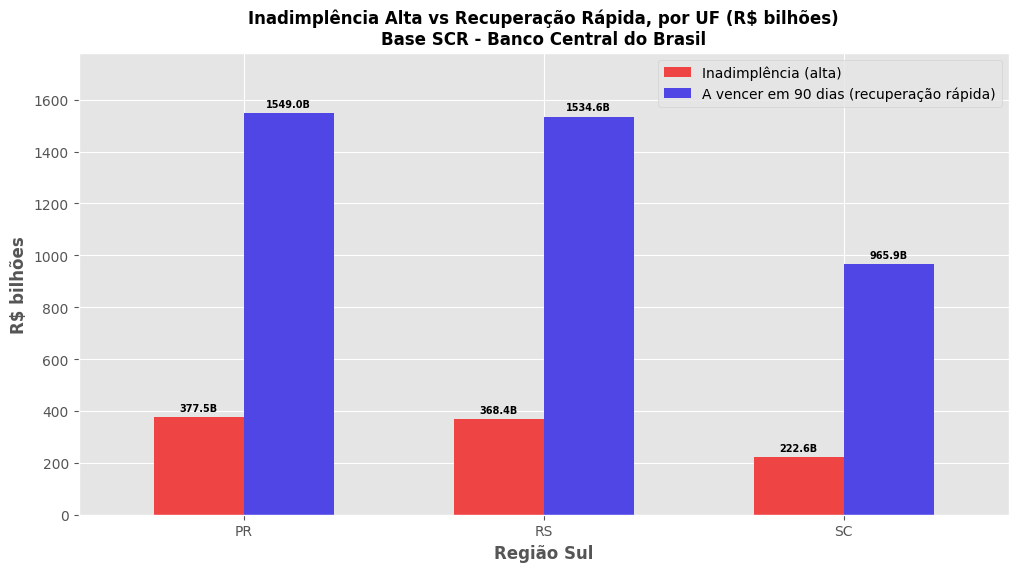

In [ ]:
# Soma as duas colunas para cada UF
tabela_inadimplencia = tabela_pf.groupby("uf").agg(
    inadimplencia=("carteira_inadimplencia", "sum"),   # total inadimplente
    a_vencer_90d=("a_vencer_ate_90_dias", "sum")       # total que vence em até 90 dias
).reset_index()                                         # uf volta a ser uma coluna normal

# Converte pra bilhões só pra ficar fácil de ler no gráfico (1e9 = 1 bilhão)
tabela_inadimplencia["inadimplencia_bi"] = tabela_inadimplencia["inadimplencia"] / 1e9
tabela_inadimplencia["a_vencer_90d_bi"] = tabela_inadimplencia["a_vencer_90d"] / 1e9

# Pergunta a região pelo menu (Enter = Norte + Nordeste)
regiao_inadimplencia, ufs_inadimplencia = escolher_regiao()

# Fica só com as UFs escolhidas e ordena da maior inadimplência pra menor
grafico_inadimplencia = tabela_inadimplencia[tabela_inadimplencia["uf"].isin(ufs_inadimplencia)]
grafico_inadimplencia = grafico_inadimplencia.sort_values(by="inadimplencia_bi", ascending=False)

plt.style.use("ggplot")   # estilo visual do gráfico

# Gráfico de barras: uma barra vermelha (inadimplência) e uma azul (90 dias) por UF
eixo = grafico_inadimplencia.set_index("uf")[["inadimplencia_bi", "a_vencer_90d_bi"]].plot(
    kind="bar", figsize=(12, 6), color=["#ef4444", "#4f46e5"], width=0.6
)

# Escreve o valor em cima de cada barra
for barra in eixo.patches:
    altura = barra.get_height()   # a altura da barra é o próprio valor
    eixo.annotate(f"{altura:.1f}B", (barra.get_x() + barra.get_width() / 2, altura),
                  ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
                  fontweight="bold", fontsize=7)

plt.title("Inadimplência Alta vs Recuperação Rápida, por UF (R$ bilhões)\nBase SCR - Banco Central do Brasil",
          fontweight="bold", fontsize=12)
plt.xlabel(f"Região {regiao_inadimplencia}", fontweight="bold")
plt.ylabel("R$ bilhões", fontweight="bold")
plt.xticks(rotation=0)                                       # nomes das UFs na horizontal
plt.legend(["Inadimplência (alta)", "A vencer em 90 dias (recuperação rápida)"])
plt.ylim(0, grafico_inadimplencia[["inadimplencia_bi", "a_vencer_90d_bi"]].values.max() * 1.15)  # 15% de folga pro número não cortar
plt.savefig("/content/grafico_inadimplencia_uf.png", bbox_inches="tight")   # salva a imagem
plt.show()

---

Inadimplência alta vs recuperação rápida, por região

---

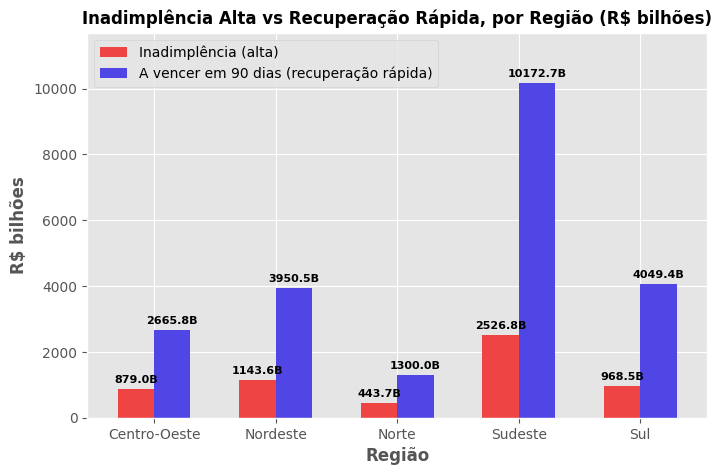

In [ ]:
# Põe em cada UF o nome da sua região (usando o dicionário mapa_regiao)
tabela_inadimplencia["regiao"] = tabela_inadimplencia["uf"].map(mapa_regiao)

# Soma as UFs de cada região
inadimplencia_regiao = tabela_inadimplencia.groupby("regiao").agg(
    inadimplencia_bi=("inadimplencia_bi", "sum"),
    a_vencer_90d_bi=("a_vencer_90d_bi", "sum")
).reset_index()

eixo = inadimplencia_regiao.set_index("regiao")[["inadimplencia_bi", "a_vencer_90d_bi"]].plot(
    kind="bar", figsize=(8, 5), color=["#ef4444", "#4f46e5"], width=0.6
)
for barra in eixo.patches:
    altura = barra.get_height()
    eixo.annotate(f"{altura:.1f}B", (barra.get_x() + barra.get_width() / 2, altura),
                  ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
                  fontweight="bold", fontsize=8)

plt.title("Inadimplência Alta vs Recuperação Rápida, por Região (R$ bilhões)", fontweight="bold", fontsize=12)
plt.xlabel("Região", fontweight="bold")
plt.ylabel("R$ bilhões", fontweight="bold")
plt.xticks(rotation=0)
plt.legend(["Inadimplência (alta)", "A vencer em 90 dias (recuperação rápida)"])
plt.ylim(0, inadimplencia_regiao[["inadimplencia_bi", "a_vencer_90d_bi"]].values.max() * 1.15)
plt.savefig("/content/grafico_inadimplencia_regiao.png", bbox_inches="tight")
plt.show()


---

% de dívida saudável vs crítica, por UF

---

Escolha a região:
  0. Norte + Nordeste
  1. Norte
  2. Nordeste
  3. Centro-Oeste
  4. Sudeste
  5. Sul
Digite o número (Enter = 0): 5


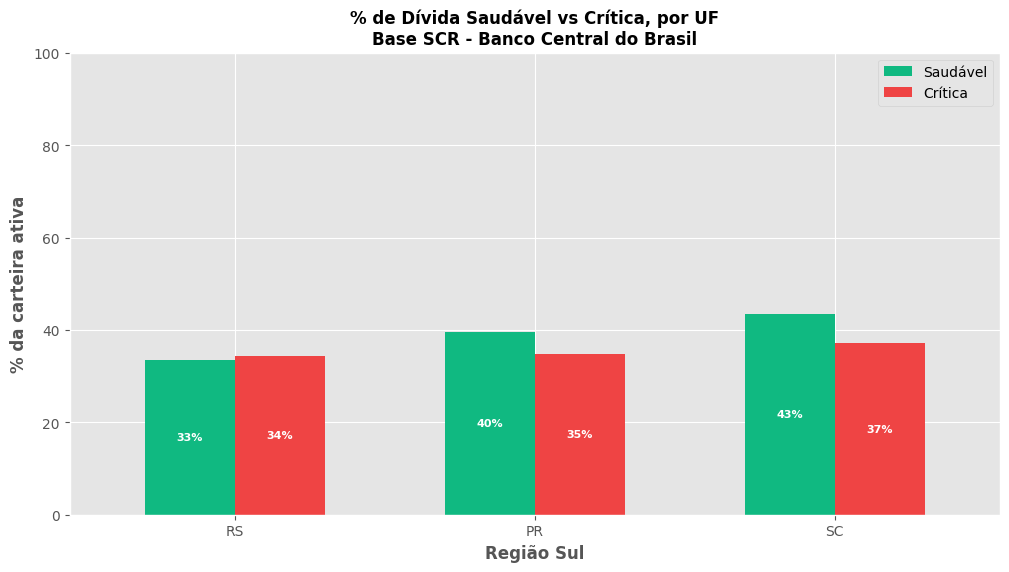

In [ ]:
# Submodalidades consideradas saudáveis
submod_saudaveis = [
    "Aquisição de bens - veículos automotores",
    "Aquisição de bens com interveniência - veículos autom.",
    "Arrendamento financeiro de veículos automotores",
    "Arrendamento financeiro exceto veículos automotores e imóveis",
    "Financiamento de projeto",
    "Financiamento habitacional - SFH",
    "Financiamento habitacional - exceto SFH",
    "Financiamento imobiliário - empreendim, exceto habitac.",
    "Financiamentos agroindustriais",
    "Home Equity"
]

# Submodalidades consideradas críticas
submod_criticas = [
    "Antecipação de fatura de cartão de crédito",
    "Aquisição de bens com interveniência - outros bens",
    "Cartão de crédito - compra à vista e parcelado lojista",
    "Cartão de crédito - compra, fatura parcelada ou saque financiado pela instituição financeira emitente do cartão",
    "Cheque especial",
    "Crédito pessoal - com consignação em folha de pagam.",
    "Crédito pessoal - sem consignação em folha de pagam.",
    "Crédito rotativo vinculado a cartão de crédito",
    "Microcrédito",
    "Outros com característica de crédito",
    "Outros empréstimos",
    "Outros financiamentos"
]

# Alguns nomes vêm com um travessão ("\x96") no lugar do hífen.
# Aqui tiramos espaços das pontas e trocamos o travessão por hífen, senão
# o nome não bate com as listas acima.
submod_limpa = tabela_pf["submodalidade"].str.strip().str.replace("\x96", "-", regex=False)

# Cria duas colunas novas: o valor da carteira só nas linhas saudáveis (ou críticas).
# .where(condição, 0) mantém o valor quando a condição é verdadeira e põe 0 quando não é.
tabela_pf["carteira_saudavel"] = tabela_pf["carteira_ativa"].where(submod_limpa.isin(submod_saudaveis), 0)
tabela_pf["carteira_critica"] = tabela_pf["carteira_ativa"].where(submod_limpa.isin(submod_criticas), 0)

# Soma por UF
tabela_divida = tabela_pf.groupby("uf").agg(
    carteira_saudavel=("carteira_saudavel", "sum"),
    carteira_critica=("carteira_critica", "sum"),
    carteira_ativa_total=("carteira_ativa", "sum")
).reset_index()

# Porcentagem da carteira total que é saudável e que é crítica
tabela_divida["percentual_saudavel"] = (tabela_divida["carteira_saudavel"] / tabela_divida["carteira_ativa_total"]) * 100
tabela_divida["percentual_critica"] = (tabela_divida["carteira_critica"] / tabela_divida["carteira_ativa_total"]) * 100

# O que não está em nenhuma das duas listas
tabela_divida["percentual_outra"] = 100 - tabela_divida["percentual_saudavel"] - tabela_divida["percentual_critica"]

# Pergunta a região e filtra as UFs, da menos crítica pra mais crítica
regiao_divida, ufs_divida = escolher_regiao()
grafico_divida = tabela_divida[tabela_divida["uf"].isin(ufs_divida)].sort_values(by="percentual_critica")

# Barras uma ao lado da outra: verde = saudável, vermelho = crítica
eixo = grafico_divida.set_index("uf")[["percentual_saudavel", "percentual_critica"]].plot(
    kind="bar", figsize=(12, 6), color=["#10b981", "#ef4444"], width=0.6, legend=False
)

for barra in eixo.patches:
    altura = barra.get_height()
    if altura > 1:   # só escreve se a barra for alta o bastante pra caber o número
        eixo.annotate(f"{altura:.0f}%", (barra.get_x() + barra.get_width() / 2, barra.get_y() + altura / 2),
                      ha="center", va="center", fontweight="bold", fontsize=8, color="white")

plt.title("% de Dívida Saudável vs Crítica, por UF\nBase SCR - Banco Central do Brasil", fontweight="bold", fontsize=12)
plt.xlabel(f"Região {regiao_divida}", fontweight="bold")
plt.ylabel("% da carteira ativa", fontweight="bold")
plt.xticks(rotation=0)
plt.legend(["Saudável", "Crítica"])
plt.ylim(0, 100)
plt.savefig("/content/grafico_divida_uf.png", bbox_inches="tight")
plt.show()

---

% de dívida saudável vs crítica, por região

---

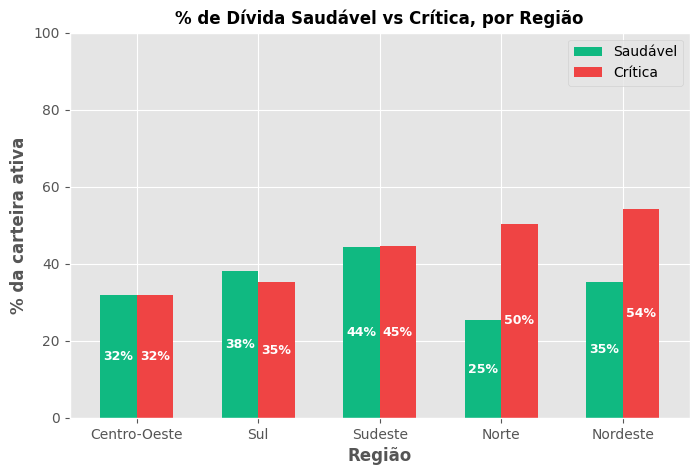

In [ ]:
# Põe a região em cada UF e soma as UFs de cada região
tabela_divida["regiao"] = tabela_divida["uf"].map(mapa_regiao)
divida_regiao = tabela_divida.groupby("regiao").agg(
    carteira_saudavel=("carteira_saudavel", "sum"),
    carteira_critica=("carteira_critica", "sum"),
    carteira_ativa_total=("carteira_ativa_total", "sum")
).reset_index()

# Recalcula as porcentagens com os totais da região (não dá pra tirar média das % das UFs)
divida_regiao["percentual_saudavel"] = (divida_regiao["carteira_saudavel"] / divida_regiao["carteira_ativa_total"]) * 100
divida_regiao["percentual_critica"] = (divida_regiao["carteira_critica"] / divida_regiao["carteira_ativa_total"]) * 100
divida_regiao = divida_regiao.sort_values(by="percentual_critica")

eixo = divida_regiao.set_index("regiao")[["percentual_saudavel", "percentual_critica"]].plot(
    kind="bar", figsize=(8, 5), color=["#10b981", "#ef4444"], width=0.6, legend=False
)
for barra in eixo.patches:
    altura = barra.get_height()
    if altura > 1:
        eixo.annotate(f"{altura:.0f}%", (barra.get_x() + barra.get_width() / 2, barra.get_y() + altura / 2),
                      ha="center", va="center", fontweight="bold", fontsize=9, color="white")

plt.title("% de Dívida Saudável vs Crítica, por Região", fontweight="bold", fontsize=12)
plt.xlabel("Região", fontweight="bold")
plt.ylabel("% da carteira ativa", fontweight="bold")
plt.xticks(rotation=0)
plt.legend(["Saudável", "Crítica"])
plt.ylim(0, 100)
plt.savefig("/content/grafico_divida_regiao.png", bbox_inches="tight")
plt.show()